# Statistical Association of Gov/Non-Gov Co-Funding in BC

This analysis examines whether the presence of non-government funders is statistically associated with the presence of government funders in BC publications.

A 2×2 contingency table is constructed based on the presence or absence of government and non-government funders. A Chi-square test of independence is used to assess the overall association between the two funding sectors.

In [1]:
import ast
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf

## 1. Configuration

In [2]:
# =============================================================================
# File paths
# =============================================================================

BC_FILE = Path(
    "./BC_data_cleaned_with_OND_Class.csv"
)

OUTPUT_DIR = Path(
    "./BC_gov_non-gov_association_analysis"
)

TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# =============================================================================
# Column names
# =============================================================================

YEAR_COLUMN = "Year"
JOURNAL_COLUMN = "Source title"
FUNDING_CLASS_COLUMN = "Funding_Details_OND_Class"

## 2. Load data

In [3]:
# =============================================================================
# Load the BC dataset
# =============================================================================

bc_df = pd.read_csv(
    BC_FILE,
    encoding="utf-8-sig"
)

print(
    f"Number of BC publications: "
    f"{len(bc_df):,}"
)

Number of BC publications: 72,714


## 3. Create gov/non-gov presence variables

In [4]:
# =============================================================================
# Parse funding organization-class pairs
# =============================================================================

def parse_funding_class_pairs(value):
    """
    Convert a string representation of organization-class pairs
    into a Python list.
    """

    if pd.isna(value):
        return []

    if isinstance(value, list):
        return value

    try:
        parsed_value = ast.literal_eval(
            value
        )

        if isinstance(
            parsed_value,
            list
        ):
            return parsed_value

        return []

    except (
        ValueError,
        SyntaxError
    ):
        return []

In [5]:
# =============================================================================
# Create binary indicators for government and non-government funding
# =============================================================================

def identify_sector_presence(value):
    """
    Identify the presence of government and non-government funders.

    Class 1 = Government
    Class 0 = Non-government
    """

    funding_pairs = parse_funding_class_pairs(
        value
    )

    classes = {
        int(organization_class)
        for organization, organization_class
        in funding_pairs
        if organization_class is not None
    }

    government_present = int(
        1 in classes
    )

    non_government_present = int(
        0 in classes
    )

    return pd.Series(
        [
            government_present,
            non_government_present
        ]
    )


bc_df[
    [
        "Government_Present",
        "Non_Government_Present"
    ]
] = bc_df[
    FUNDING_CLASS_COLUMN
].apply(
    identify_sector_presence
)

In [6]:
# =============================================================================
# Check government and non-government funding combinations
# =============================================================================

print(
    bc_df
    .groupby(
        [
            "Government_Present",
            "Non_Government_Present"
        ]
    )
    .size()
)

Government_Present  Non_Government_Present
0                   0                         22399
                    1                          8752
1                   0                         20721
                    1                         20842
dtype: int64


## 4. Overall 2×2 contingency table

In [7]:
# =============================================================================
# Create the 2×2 contingency table
# =============================================================================

contingency_table = pd.crosstab(
    bc_df[
        "Non_Government_Present"
    ],
    bc_df[
        "Government_Present"
    ]
)

# Ensure a consistent 2×2 structure.
contingency_table = (
    contingency_table
    .reindex(
        index=[0, 1],
        columns=[0, 1],
        fill_value=0
    )
)

contingency_table.index = [
    "Non-government absent",
    "Non-government present"
]

contingency_table.columns = [
    "Government absent",
    "Government present"
]

display(
    contingency_table
)

,Government absent,Government present
Non-government absent,22399,20721
Non-government present,8752,20842


## 5. Chi-square test

In [8]:
# =============================================================================
# Chi-square test of independence
# =============================================================================

chi2, p_value, dof, expected = (
    stats.chi2_contingency(
        contingency_table,
        correction=False
    )
)

# =============================================================================
# Format the p-value
# =============================================================================

if p_value < 0.0001:
    p_text = "p < .0001"
else:
    p_text = f"p = {p_value:.4f}"


# =============================================================================
# Display Chi-square test results
# =============================================================================

print(
    f"Chi-square statistic: {chi2:.4f}"
)

print(
    f"Degrees of freedom: {dof}"
)

print(
    p_text
)

Chi-square statistic: 3587.0532
Degrees of freedom: 1
p < .0001


## 5-1. Effect size: Phi coefficient 

In [9]:
# =============================================================================
# Calculate the Phi coefficient
# =============================================================================

n = contingency_table.to_numpy().sum()

phi = np.sqrt(
    chi2 / n
)

print(
    f"Phi coefficient: {phi:.4f}"
)

Phi coefficient: 0.2221


## 5-2. Odds ratio

In [10]:
# =============================================================================
# Calculate the odds ratio
# =============================================================================

table_values = contingency_table.to_numpy()

a = table_values[0, 0]
b = table_values[0, 1]
c = table_values[1, 0]
d = table_values[1, 1]

odds_ratio = (
    (a * d)
    / (b * c)
)

log_or_se = np.sqrt(
    (1 / a)
    + (1 / b)
    + (1 / c)
    + (1 / d)
)

ci_lower = np.exp(
    np.log(odds_ratio)
    - 1.96 * log_or_se
)

ci_upper = np.exp(
    np.log(odds_ratio)
    + 1.96 * log_or_se
)

print(
    f"Odds ratio: {odds_ratio:.4f}"
)

print(
    f"95% CI: "
    f"[{ci_lower:.4f}, {ci_upper:.4f}]"
)

Odds ratio: 2.5742
95% CI: [2.4949, 2.6561]


## 6. Save the results

In [11]:
# =============================================================================
# Save the overall statistical results
# =============================================================================

overall_results = pd.DataFrame(
    {
        "N": [n],
        "Chi_Square": [chi2],
        "df": [dof],
        "P_Value": [p_value],
        "Phi": [phi],
        "Odds_Ratio": [odds_ratio],
        "OR_CI_95_Lower": [ci_lower],
        "OR_CI_95_Upper": [ci_upper]
    }
)

display(
    overall_results.round(4)
)

contingency_table.to_csv(
    TABLE_DIR
    / "BC_overall_2x2_contingency_table.csv",
    encoding="utf-8-sig"
)

overall_results.to_csv(
    TABLE_DIR
    / "BC_overall_chi_square_results.csv",
    index=False,
    encoding="utf-8-sig"
)

,N,Chi_Square,df,P_Value,Phi,Odds_Ratio,OR_CI_95_Lower,OR_CI_95_Upper
0,72714,3587.0532,1,0.0,0.2221,2.5742,2.4949,2.6561


## 7. Temporal analysis preparation

In [12]:
# =============================================================================
# Prepare the year variable for temporal logistic regression
# =============================================================================

bc_df[
    YEAR_COLUMN
] = pd.to_numeric(
    bc_df[
        YEAR_COLUMN
    ],
    errors="coerce"
)

temporal_df = bc_df[
    bc_df[
        YEAR_COLUMN
    ].between(
        2009,
        2020
    )
].copy()

temporal_df[
    "Year_Centered"
] = (
    temporal_df[
        YEAR_COLUMN
    ]
    - 2009
)

## 7-1. Logistic regression

In [13]:
# =============================================================================
# Temporal logistic regression with interaction
# =============================================================================

temporal_model = smf.logit(
    formula=(
        "Non_Government_Present ~ "
        "Government_Present * Year_Centered"
    ),
    data=temporal_df
).fit()

print(
    temporal_model.summary()
)

Optimization terminated successfully.
         Current function value: 0.649819
         Iterations 5
                             Logit Regression Results                             
Dep. Variable:     Non_Government_Present   No. Observations:                72714
Model:                              Logit   Df Residuals:                    72710
Method:                               MLE   Df Model:                            3
Date:                    Tue, 18 Aug 2026   Pseudo R-squ.:                 0.03837
Time:                            22:44:44   Log-Likelihood:                -47251.
converged:                           True   LL-Null:                       -49136.
Covariance Type:                nonrobust   LLR p-value:                     0.000
                                       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------------
Intercept                       

## 7-2. Odds ratios

In [14]:
# =============================================================================
# Convert logistic regression coefficients to odds ratios
# =============================================================================

temporal_conf_int = (
    temporal_model.conf_int()
)

temporal_results = pd.DataFrame(
    {
        "Coefficient":
            temporal_model.params,

        "Odds_Ratio":
            np.exp(
                temporal_model.params
            ),

        "CI_95_Lower":
            np.exp(
                temporal_conf_int[0]
            ),

        "CI_95_Upper":
            np.exp(
                temporal_conf_int[1]
            ),

        "P_Value":
            temporal_model.pvalues
    }
)

display(
    temporal_results.round(4)
)

,Coefficient,Odds_Ratio,CI_95_Lower,CI_95_Upper,P_Value
Intercept,-1.1744,0.3090,0.2933,0.3256,0.0
Government_Present,1.2405,3.4573,3.2352,3.6948,0.0
Year_Centered,0.0372,1.0379,1.0305,1.0454,0.0
Government_Present:Year_Centered,-0.0466,0.9544,0.9458,0.9632,0.0


## 8. Overall BC: 2×2 contingency heatmap

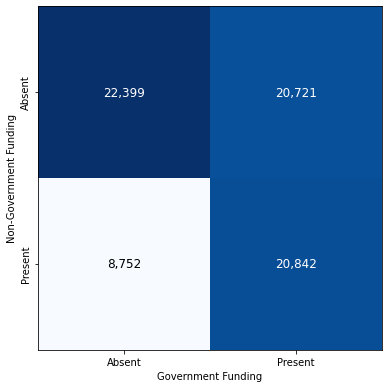

In [15]:
import matplotlib.pyplot as plt
import numpy as np


# =============================================================================
# Visualize the overall 2×2 contingency table
# =============================================================================

table_values = contingency_table.to_numpy()

fig, ax = plt.subplots(
    figsize=(7, 5.5)
)

# Use a sequential blue color palette for the heatmap.
image = ax.imshow(
    table_values,
    cmap="Blues"
)


# =============================================================================
# Add cell counts with adaptive text colors
# =============================================================================

# Use the midpoint of the heatmap color scale as the threshold.
threshold = (
    table_values.min()
    + table_values.max()
) / 2

for i in range(table_values.shape[0]):
    for j in range(table_values.shape[1]):

        cell_value = table_values[i, j]

        # Use white text for dark cells and black text for light cells.
        text_color = (
            "white"
            if cell_value > threshold
            else "black"
        )

        ax.text(
            j,
            i,
            f"{cell_value:,}",
            ha="center",
            va="center",
            fontsize=12,
            color=text_color
        )


# =============================================================================
# Customize axis labels
# =============================================================================

ax.set_xticks(
    [0, 1]
)

ax.set_xticklabels(
    [
        "Absent",
        "Present"
    ]
)

ax.set_yticks(
    [0, 1]
)

ax.set_yticklabels(
    [
        "Absent",
        "Present"
    ],
    rotation=90,
    va="center"
)

ax.set_xlabel(
    "Government Funding"
)

ax.set_ylabel(
    "Non-Government Funding"
)

# ax.set_title(
#     "Co-occurrence of Government and Non-Government Funding in BC"
# )

# =============================================================================
# Save the figure
# =============================================================================

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "BC_overall_2x2_contingency_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 9. Overall BC: Odds Ratio + 95% CI visualization

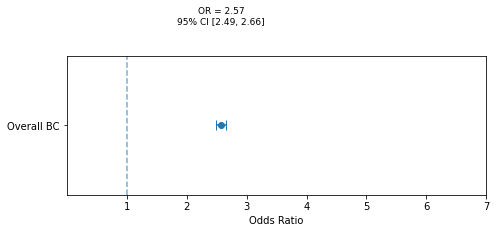

In [21]:
# =============================================================================
# Visualize the overall odds ratio and 95% confidence interval
# =============================================================================

fig, ax = plt.subplots(
    figsize=(7, 3.5)
)

ax.errorbar(
    x=odds_ratio,
    y=0,
    xerr=[
        [
            odds_ratio - ci_lower
        ],
        [
            ci_upper - odds_ratio
        ]
    ],
    fmt="o",
    capsize=5
)

# OR = 1 indicates no association.
ax.axvline(
    x=1,
    linestyle="--",
    alpha=0.6
)

ax.set_yticks(
    [0]
)

ax.set_yticklabels(
    ["Overall BC"]
)

ax.set_xlabel(
    "Odds Ratio"
)

# ax.set_title(
#     "Association Between Government and Non-Government Funding"
# )

# =============================================================================
# Customize x-axis range and tick positions
# =============================================================================

ax.set_xlim(
    0,
    7
)

ax.set_xticks(
    [1, 2, 3, 4, 5, 6, 7]
)

# =============================================================================
# Add odds ratio and confidence interval
# =============================================================================

ax.text(
    odds_ratio,
    0.08,
    (
        f"OR = {odds_ratio:.2f}\n"
        f"95% CI [{ci_lower:.2f}, {ci_upper:.2f}]"
    ),
    ha="center",
    fontsize=9
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "BC_overall_odds_ratio.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 10. Temporal analysis visualization

In [17]:
# =============================================================================
# Calculate predicted probabilities from the temporal logistic model
# =============================================================================

prediction_years = np.arange(
    2009,
    2021
)

prediction_df = pd.DataFrame(
    {
        "Year": np.repeat(
            prediction_years,
            2
        ),

        "Year_Centered": np.repeat(
            prediction_years - 2009,
            2
        ),

        "Government_Present": np.tile(
            [0, 1],
            len(prediction_years)
        )
    }
)

prediction_df[
    "Predicted_Probability"
] = temporal_model.predict(
    prediction_df
)

prediction_df[
    "Government_Status"
] = prediction_df[
    "Government_Present"
].map(
    {
        0: "Absent",
        1: "Present"
    }
)

display(
    prediction_df.head()
)

,Year,Year_Centered,Government_Present,Predicted_Probability,Government_Status
0,2009,0,0,0.236068,Absent
1,2009,0,1,0.516528,Present
2,2010,1,0,0.242841,Absent
3,2010,1,1,0.514173,Present
4,2011,2,0,0.249745,Absent


In [18]:
# =============================================================================
# Extract the temporal interaction effect
# =============================================================================

interaction_term = (
    "Government_Present:Year_Centered"
)

interaction_beta = (
    temporal_model.params[
        interaction_term
    ]
)

interaction_p = (
    temporal_model.pvalues[
        interaction_term
    ]
)

interaction_or = np.exp(
    interaction_beta
)

print(
    f"Interaction beta: "
    f"{interaction_beta:.4f}"
)

print(
    f"Interaction OR: "
    f"{interaction_or:.4f}"
)

print(
    f"P-value: "
    f"{interaction_p:.4g}"
)

Interaction beta: -0.0466
Interaction OR: 0.9544
P-value: 1.654e-23


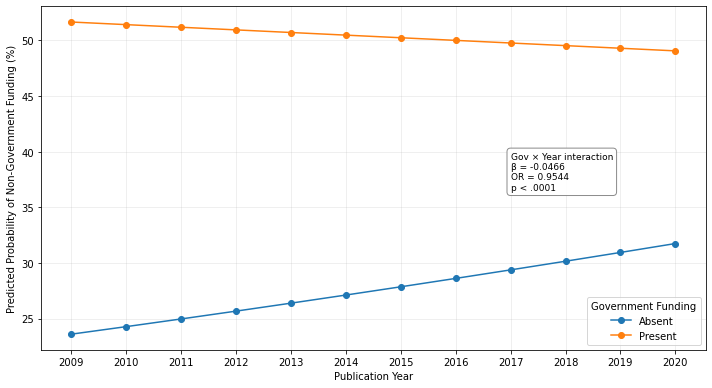

In [19]:
# =============================================================================
# Plot temporal predicted probabilities
# =============================================================================

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

for government_status in [
    "Absent",
    "Present"
]:

    subset = prediction_df[
        prediction_df[
            "Government_Status"
        ]
        == government_status
    ]

    ax.plot(
        subset["Year"],
        subset[
            "Predicted_Probability"
        ] * 100,
        marker="o",
        label=government_status
    )

# =============================================================================
# Add interaction annotation
# =============================================================================

interaction_text = (
    "Gov × Year interaction\n"
    f"β = {interaction_beta:.4f}\n"
    f"OR = {interaction_or:.4f}\n"
    "p < .0001"
)

ax.text(
    2017.0,
    40.0,
    interaction_text,
    fontsize=9,
    ha="left",
    va="top",
    bbox=dict(
        boxstyle="round,pad=0.4",
        facecolor="white",
        edgecolor="gray",
        alpha=0.9
    )
)    


# =============================================================================
# Format the figure
# =============================================================================
   
ax.set_xlabel(
    "Publication Year"
)

ax.set_ylabel(
    "Predicted Probability of Non-Government Funding (%)"
)

ax.set_xticks(
    prediction_years
)

ax.legend(
    title="Government Funding"
)

ax.grid(
    alpha=0.25
)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR
    / "BC_temporal_predicted_probability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()